# Estudo guiado — Capítulo 3: mecanismos de atenção

Este notebook acompanha o capítulo 3 do repositório **LLMs-from-scratch**. Vamos construir a atenção em PyTorch em etapas pequenas, executar cada trecho e conferir as dimensões e os resultados.

## Roteiro de tarefas

1. Importar bibliotecas e verificar o ambiente PyTorch.
2. Localizar e consultar o notebook principal do capítulo 3.
3. Criar os tensores de entrada e calcular projeções **Q, K, V** e os scores com multiplicação de matrizes.
4. Aplicar `softmax` para transformar scores em pesos que somam 1.
5. Aplicar máscara causal, preenchendo posições futuras com $-\infty$ **antes** do softmax.
6. Entender a arquitetura de Multi-Head Attention.
7. Projetar Q, K e V para todas as cabeças de uma só vez.
8. Separar as cabeças com `reshape`/`transpose`, calcular em paralelo e concatenar.
9. Verificar dimensões, normalização e causalidade com asserts.
10. Visualizar e interpretar os pesos de atenção.
11. Relacionar overfitting com as etapas de treinamento que virão depois.

> **Importante:** este capítulo ensina mecanismos de atenção; sozinho, não treina um ChatGPT nem resolve overfitting. A meta de longo prazo pode ser construir um GPT-2 simplificado. Regularização (por exemplo, dropout), dados de validação e monitoramento da diferença entre treino e validação serão relevantes nas etapas de treinamento posteriores.

**Como usar:** execute as células em ordem. Nas partes marcadas como desafio, primeiro preveja o resultado; depois altere os valores e execute novamente.

In [9]:
# Instalação para CPU; evita baixar as dependências CUDA volumosas.
%pip install torch --index-url https://download.pytorch.org/whl/cpu
%pip install numpy matplotlib

Looking in indexes: https://download.pytorch.org/whl/cpu
Public/.venv/lib/python3.10/site-packages (2.14.1+cpu)
Public/.venv/lib/python3.10/site-packages (from torch) (78.1.0)
Public/.venv/lib/python3.10/site-packages (from torch) (2026.9.0)
Public/.venv/lib/python3.10/site-packages (from torch) (4.1.0)
Public/.venv/lib/python3.10/site-packages (from torch) (3.1.6)
Public/.venv/lib/python3.10/site-packages (from torch) (4.16.0)
Public/.venv/lib/python3.10/site-packages (from torch) (3.4.2)
Public/.venv/lib/python3.10/site-packages (from torch) (1.14.0)
Public/.venv/lib/python3.10/site-packages (from sympy>=1.13.3->torch) (1.3.0)
Public/.venv/lib/python3.10/site-packages (from jinja2->torch) (3.0.4)
You should consider upgrading via the '/home/danielanderson.silva.copin/Downloads/transformer-model-engineering
Public/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Public/.venv/lib/python3.10/site-packages (2.2.6)
P

In [1]:
# 1. Bibliotecas e ambiente
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

print("PyTorch:", torch.__version__)
print("Dispositivo:", "CUDA" if torch.cuda.is_available() else "CPU")
torch.manual_seed(123)

# Pequeno exemplo didático: 4 tokens, cada um representado por 3 números.
X = torch.tensor([
    [1.0, 0.0, 1.0],
    [0.0, 2.0, 1.0],
    [1.0, 1.0, 0.0],
    [0.0, 1.0, 2.0],
])
print("\nX (tokens × dimensões):\n", X)
print("shape de X:", tuple(X.shape))

Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.14.1+cpu
Dispositivo: CPU

X (tokens × dimensões):
 tensor([[1., 0., 1.],
        [0., 2., 1.],
        [1., 1., 0.],
        [0., 1., 2.]])
shape de X: (4, 3)


## 2. Consultar o código do capítulo 3

O notebook principal está em `01_main-chapter-code/ch03.ipynb`. A célula abaixo procura o arquivo a partir da pasta atual ou de suas pastas ancestrais, lê o notebook e mostra pequenos trechos relacionados a atenção causal e Multi-Head Attention. Use os trechos para comparar a nossa implementação com a do capítulo.

In [2]:
# 2. Localizar e ler o notebook oficial sem executar suas células
candidates = []
for base in (Path.cwd(), *Path.cwd().parents):
    candidates.extend([
        base / "ch03" / "01_main-chapter-code" / "ch03.ipynb",
        base / "01_main-chapter-code" / "ch03.ipynb",
    ])
chapter_notebook = next((path for path in candidates if path.is_file()), None)

if chapter_notebook is None:
    print("Não encontrei o notebook automaticamente.")
    print("Abra o notebook a partir da pasta do repositório ou ajuste chapter_notebook.")
else:
    chapter_data = json.loads(chapter_notebook.read_text(encoding="utf-8"))
    print("Referência:", chapter_notebook)
    terms = ("class CausalAttention", "class MultiHeadAttention", "class SelfAttention_v2")
    for term in terms:
        match = next(
            (cell.get("source", []) for cell in chapter_data["cells"]
             if cell.get("cell_type") == "code" and term in "".join(cell.get("source", []))),
            None,
        )
        if match:
            source = "".join(match)
            start = source.find(term)
            print(f"\n--- Trecho de referência: {term} ---\n")
            print(source[start:start + 900])

Referência: /home/danielanderson.silva.copin/Downloads/transformer-model-engineering
Public/LLMs-from-scratch/ch03/01_main-chapter-code/ch03.ipynb

--- Trecho de referência: class CausalAttention ---

class CausalAttention(nn.Module):

    def __init__(self, d_in, d_out, context_length,
                 dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout) # New
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1)) # New

    def forward(self, x):
        b, num_tokens, d_in = x.shape # New batch dimension b
        # For inputs where `num_tokens` exceeds `context_length`, this will result in errors
        # in the mask creation further below.
        # In practice, this is not a problem

## 3. Calcular as matrizes de atenção: Q, K e V

Cada token passa por projeções lineares para obter **Q** (query), **K** (key) e **V** (value). Para visualizar a matemática, começamos com matrizes pequenas e fixas; mais adiante, as projeções serão parâmetros aprendidos. O produto $QK^T$ compara cada query com as keys.

In [3]:
# 3. Uma cabeça de atenção, com projeções lineares didáticas
W_q = torch.tensor([[0.2, 0.1, 0.0], [0.0, 0.3, 0.1], [0.1, 0.0, 0.2]])
W_k = torch.tensor([[0.3, 0.0, 0.1], [0.1, 0.2, 0.0], [0.0, 0.1, 0.3]])
W_v = torch.tensor([[0.2, 0.0, 0.1], [0.0, 0.2, 0.1], [0.1, 0.1, 0.2]])

Q = X @ W_q
K = X @ W_k
V = X @ W_v
scores = Q @ K.T
scaled_scores = scores / math.sqrt(K.shape[-1])

print("Q shape:", tuple(Q.shape), " K shape:", tuple(K.shape), " V shape:", tuple(V.shape))
print("Scores brutos Q @ K.T:\n", scores)
print("Scores escalados por sqrt(d_k):\n", scaled_scores)

Q shape: (4, 3)  K shape: (4, 3)  V shape: (4, 3)
Scores brutos Q @ K.T:
 tensor([[0.1800, 0.1700, 0.1600, 0.1900],
        [0.2500, 0.4400, 0.2000, 0.4900],
        [0.1400, 0.2700, 0.1700, 0.2400],
        [0.2900, 0.3400, 0.1900, 0.4400]])
Scores escalados por sqrt(d_k):
 tensor([[0.1039, 0.0981, 0.0924, 0.1097],
        [0.1443, 0.2540, 0.1155, 0.2829],
        [0.0808, 0.1559, 0.0981, 0.1386],
        [0.1674, 0.1963, 0.1097, 0.2540]])


## 4. Aplicar softmax

O softmax é aplicado linha a linha (na última dimensão): cada token de entrada obtém uma distribuição de pesos sobre os tokens que pode consultar. Valores grandes recebem mais peso; cada linha deve somar 1.

In [4]:
# 4. Normalizar scores e combinar os valores V
attention_weights = torch.softmax(scaled_scores, dim=-1)
context = attention_weights @ V

print("Pesos de atenção:\n", attention_weights)
print("Soma por linha:", attention_weights.sum(dim=-1))
print("Representações contextuais (pesos @ V):\n", context)

Pesos de atenção:
 tensor([[0.2507, 0.2493, 0.2478, 0.2522],
        [0.2361, 0.2634, 0.2293, 0.2712],
        [0.2407, 0.2594, 0.2449, 0.2550],
        [0.2461, 0.2533, 0.2323, 0.2683]])
Soma por linha: tensor([1.0000, 1.0000, 1.0000, 1.0000])
Representações contextuais (pesos @ V):
 tensor([[0.2001, 0.3001, 0.3506],
        [0.1973, 0.3097, 0.3576],
        [0.1981, 0.3048, 0.3525],
        [0.1993, 0.3050, 0.3558]])


## 5. Máscara causal com $-\infty$

Na geração autoregressiva, o token na posição $t$ não pode consultar posições posteriores a $t$. Criamos uma máscara triangular superior e substituímos esses scores por $-\infty$ **antes** do softmax. Como $e^{-\infty}=0$, as posições futuras recebem peso exatamente zero.

In [5]:
# 5. Aplicar máscara causal
seq_len = scaled_scores.shape[-1]
future_mask = torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool), diagonal=1)
masked_scores = scaled_scores.masked_fill(future_mask, float("-inf"))
causal_weights = torch.softmax(masked_scores, dim=-1)
causal_context = causal_weights @ V

print("Máscara (True = posição futura bloqueada):\n", future_mask)
print("Scores mascarados:\n", masked_scores)
print("Pesos causais:\n", causal_weights)
print("Somas das linhas:", causal_weights.sum(dim=-1))
print("Contexto causal:\n", causal_context)

Máscara (True = posição futura bloqueada):
 tensor([[False,  True,  True,  True],
        [False, False,  True,  True],
        [False, False, False,  True],
        [False, False, False, False]])
Scores mascarados:
 tensor([[0.1039,   -inf,   -inf,   -inf],
        [0.1443, 0.2540,   -inf,   -inf],
        [0.0808, 0.1559, 0.0981,   -inf],
        [0.1674, 0.1963, 0.1097, 0.2540]])
Pesos causais:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.4726, 0.5274, 0.0000, 0.0000],
        [0.3231, 0.3482, 0.3287, 0.0000],
        [0.2461, 0.2533, 0.2323, 0.2683]])
Somas das linhas: tensor([1.0000, 1.0000, 1.0000, 1.0000])
Contexto causal:
 tensor([[0.3000, 0.1000, 0.3000],
        [0.1945, 0.3110, 0.3527],
        [0.1975, 0.2722, 0.3020],
        [0.1993, 0.3050, 0.3558]])


## 6–8. Multi-Head Attention: projetar, separar, processar em paralelo e concatenar

A ideia é **projetar cada token para as dimensões de todas as cabeças de uma só vez**. Em seguida, reorganizamos as dimensões com `reshape` e `transpose`: as cabeças ficam em um eixo próprio e o PyTorch calcula suas atenções em paralelo por operações em lote. Ao final, juntamos as cabeças (`concat`) e aplicamos uma projeção de saída.

Nesta demonstração, uma projeção linear combinada gera Q, K e V; cada um tem espaço suficiente para todas as cabeças. A separação em cabeças é apenas uma reorganização lógica dos tensores — não é necessário criar uma camada linear independente para cada cabeça.

In [6]:
# 6–8. Projeção conjunta QKV e divisão lógica em cabeças
X_multi = torch.tensor([[[1.0, 0.0, 1.0, 0.0],
                         [0.0, 2.0, 1.0, 1.0],
                         [1.0, 1.0, 0.0, 2.0],
                         [0.0, 1.0, 2.0, 1.0]]])  # (batch=1, tokens=4, d_model=4)
batch_size, seq_len_multi, d_model = X_multi.shape
num_heads = 2
head_dim = d_model // num_heads
assert d_model % num_heads == 0

qkv_projection = nn.Linear(d_model, 3 * d_model, bias=False)
qkv_all = qkv_projection(X_multi)                 # (B, T, 3*d_model)
q_all, k_all, v_all = qkv_all.chunk(3, dim=-1)    # cada um: (B, T, d_model)

def split_heads(tensor):
    """Reorganiza (B, T, d_model) em (B, heads, T, head_dim)."""
    return tensor.reshape(batch_size, seq_len_multi, num_heads, head_dim).transpose(1, 2)

q_heads = split_heads(q_all)
k_heads = split_heads(k_all)
v_heads = split_heads(v_all)

scores_heads = q_heads @ k_heads.transpose(-2, -1) / math.sqrt(head_dim)
mask_multi = torch.triu(torch.ones(seq_len_multi, seq_len_multi, dtype=torch.bool), diagonal=1)
scores_heads = scores_heads.masked_fill(mask_multi, float("-inf"))
weights_heads = torch.softmax(scores_heads, dim=-1)
context_heads = weights_heads @ v_heads               # (B, heads, T, head_dim)
concatenated = context_heads.transpose(1, 2).contiguous().view(batch_size, seq_len_multi, d_model)
output_projection = nn.Linear(d_model, d_model, bias=False)
multihead_output = output_projection(concatenated)

print("X_multi:", tuple(X_multi.shape))
print("Projeção conjunta QKV:", tuple(qkv_all.shape))
print("Q por cabeça:", tuple(q_heads.shape), "= (batch, heads, tokens, head_dim)")
print("Pesos por cabeça:", tuple(weights_heads.shape))
print("Cabeças concatenadas:", tuple(concatenated.shape))
print("Saída projetada:", tuple(multihead_output.shape))

X_multi: (1, 4, 4)
Projeção conjunta QKV: (1, 4, 12)
Q por cabeça: (1, 2, 4, 2) = (batch, heads, tokens, head_dim)
Pesos por cabeça: (1, 2, 4, 4)
Cabeças concatenadas: (1, 4, 4)
Saída projetada: (1, 4, 4)


## 9. Testes da implementação

Os testes abaixo verificam invariantes fundamentais: dimensões esperadas, pesos normalizados, posições futuras bloqueadas e saídas finitas. Eles não provam que o modelo aprendeu uma tarefa — validam apenas o comportamento matemático básico da atenção.

In [7]:
# 9. Testes rápidos de invariantes
assert Q.shape == K.shape == V.shape == (4, 3)
assert torch.allclose(attention_weights.sum(dim=-1), torch.ones(4))
assert torch.allclose(causal_weights.sum(dim=-1), torch.ones(4))
assert torch.isneginf(masked_scores[future_mask]).all()
assert torch.count_nonzero(torch.triu(causal_weights, diagonal=1)) == 0
assert q_heads.shape == (1, 2, 4, 2)
assert weights_heads.shape == (1, 2, 4, 4)
assert torch.allclose(weights_heads.sum(dim=-1), torch.ones(1, 2, 4))
assert torch.count_nonzero(torch.triu(weights_heads, diagonal=1)) == 0
assert torch.isfinite(multihead_output).all()
print("Todos os testes passaram ✅")

Todos os testes passaram ✅


## 10. Visualizar e interpretar os pesos

Na linha $t$ da matriz, vemos quanto o token na posição $t$ atende a cada posição. Na versão causal, a região acima da diagonal deve estar zerada. Compare a atenção de uma cabeça com a de outra.

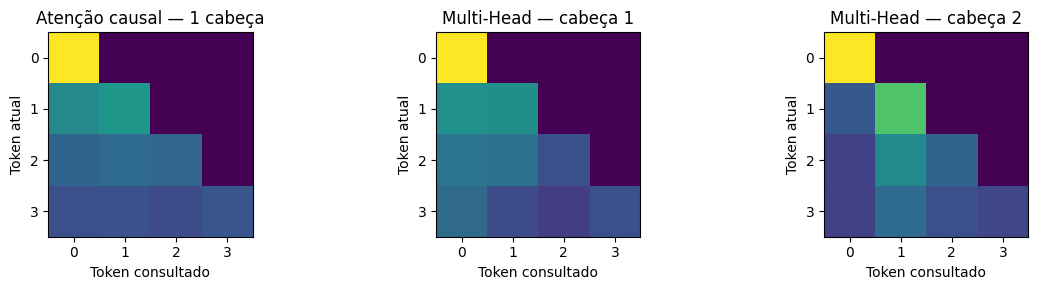

In [8]:
# 10. Mapas de calor dos pesos causais
fig, axes = plt.subplots(1, num_heads + 1, figsize=(4 * (num_heads + 1), 3))
axes[0].imshow(causal_weights.detach().numpy(), cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Atenção causal — 1 cabeça")
axes[0].set_xlabel("Token consultado")
axes[0].set_ylabel("Token atual")
for head_idx in range(num_heads):
    axes[head_idx + 1].imshow(weights_heads[0, head_idx].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
    axes[head_idx + 1].set_title(f"Multi-Head — cabeça {head_idx + 1}")
    axes[head_idx + 1].set_xlabel("Token consultado")
    axes[head_idx + 1].set_ylabel("Token atual")
plt.tight_layout()
plt.show()

## 11. Overfitting e próximos passos

**Overfitting não é resolvido pelo mecanismo de atenção sozinho.** Ele aparece durante o treinamento quando o modelo se ajusta demais aos exemplos de treino e generaliza mal. Ao chegar às etapas de treinamento, vamos acompanhar a perda de treino e validação e considerar:

- separar dados de treino e validação sem misturá-los;
- usar dropout (inclusive no bloco de atenção, quando apropriado);
- controlar o número de parâmetros e treinar por um número adequado de épocas (early stopping);
- avaliar em textos que não foram usados no treino.

O objetivo aqui é sair entendendo os blocos matemáticos necessários para avançar rumo a um **GPT-2 simplificado, com finalidade educacional**. Construir um modelo conversacional no estilo ChatGPT exigiria etapas adicionais, como pré-treinamento e ajuste para instruções.

### Checklist de entendimento

- [ ] Sei explicar o papel de Q, K e V.
- [ ] Sei por que calculamos $QK^T / \sqrt{d_k}$ antes do softmax.
- [ ] Sei por que posições futuras recebem $-\infty$ antes do softmax.
- [ ] Sei descrever os formatos antes e depois de separar as cabeças.
- [ ] Sei explicar por que a concatenação restaura a dimensão do modelo.
- [ ] Comparei a implementação com o notebook principal do capítulo 3.

**Próxima sessão:** abrir o notebook principal ao lado deste e refazer as classes `CausalAttention` e `MultiHeadAttention` sem copiar, conferindo cada dimensão.